# Exploration et préparation des données socio-économiques
> Construction de la base IRIS finale pour l'agrégation spatiale vers les bureaux de vote

## 1. Setup et chargement

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.insert(0, '/content/drive/MyDrive/Stage')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

BASE = "/content/drive/MyDrive/Stage/Agreation_Bureau_Socio/"
print(" Setup OK")

Mounted at /content/drive
 Setup OK


## 2. Base Activité-Résidents 2022

In [ ]:
# Chargement avec dtype str pour les colonnes identifiants
df = pd.read_csv(
    BASE + "base-ic-activite-residents-2022.CSV",
    sep=";",
    dtype={"IRIS": str, "COM": str, "TYP_IRIS": str},
    low_memory=False
)
print(f" Dimensions : {df.shape}")
print(f"  IRIS : {df['IRIS'].nunique():,} unités")
print(f"  Types IRIS : {df['TYP_IRIS'].value_counts().to_dict()}")
df.head(3)

 Dimensions : (49276, 119)
  IRIS : 49,276 unités
  Types IRIS : {'Z': 33036, 'H': 15010, 'A': 829, 'D': 401}


,IRIS,COM,TYP_IRIS,LAB_IRIS,P22_POP1564,P22_POP1524,P22_POP2554,P22_POP5564,P22_H1564,P22_H1524,...,P22_ACTOCC15P_ILT3,P22_ACTOCC15P_ILT4,P22_ACTOCC15P_ILT5,C22_ACTOCC15P,C22_ACTOCC15P_PAS,C22_ACTOCC15P_MAR,C22_ACTOCC15P_VELO,C22_ACTOCC15P_2ROUESMOT,C22_ACTOCC15P_VOIT,C22_ACTOCC15P_TCOM
0,010010000,01001,Z,5,525.000000,66.000000,328.000000,131.000000,262.000000,32.000000,...,99.000000,13.000000,0.0,441.771429,19.634286,0.000000,0.000000,9.817143,407.411429,4.908571
1,010020000,01002,Z,5,166.000000,25.000000,115.000000,26.000000,88.000000,17.000000,...,10.000000,5.000000,0.0,114.163636,4.963636,0.000000,0.000000,0.000000,104.236364,4.963636
2,010040101,01004,H,1,1334.374042,419.339349,752.345462,162.689232,692.816632,228.998609,...,164.753416,11.647172,0.0,979.862397,69.862125,91.821899,29.128057,9.999818,673.223356,105.827142


In [ ]:
# Types et valeurs manquantes
print("Types de colonnes :")
print(df.dtypes.value_counts())
print(f"\nValeurs manquantes : {df.isna().sum().sum()} (total)")
print(f"Colonnes avec NaN : {(df.isna().sum() > 0).sum()}")

Types de colonnes :
float64    115
object       4
Name: count, dtype: int64

Valeurs manquantes : 0 (total)
Colonnes avec NaN : 0


## 3. Sélection et création des variables socio-économiques

In [ ]:
# Variables sélectionnées — inclure C22_ACTOCC15P comme dénominateur correct
variables = [
    "IRIS", "COM", "TYP_IRIS",
    # Population active
    "P22_POP1564",
    "P22_ACT1564",
    "P22_ACTOCC1564",
    "P22_CHOM1564",
    # Modes de transport (dénominateur commun C22_ACTOCC15P obligatoire)
    "C22_ACTOCC15P",
    "C22_ACTOCC15P_VOIT",
    "C22_ACTOCC15P_TCOM",
    # Diplômes
    "P22_ACT_DIPLMIN",
    "P22_ACT_SUP2",
    "P22_ACT_SUP34",
    "P22_ACT_SUP5",
]

iris = df[variables].copy()
print(f"Base IRIS : {iris.shape}")
iris.head(3)

Base IRIS : (49276, 14)


,IRIS,COM,TYP_IRIS,P22_POP1564,P22_ACT1564,P22_ACTOCC1564,P22_CHOM1564,C22_ACTOCC15P,C22_ACTOCC15P_VOIT,C22_ACTOCC15P_TCOM,P22_ACT_DIPLMIN,P22_ACT_SUP2,P22_ACT_SUP34,P22_ACT_SUP5
0,010010000,01001,Z,525.000000,431.000000,403.000000,28.000000,441.771429,407.411429,4.908571,35.000000,75.000000,52.000000,33.000000
1,010020000,01002,Z,166.000000,133.000000,131.000000,2.000000,114.163636,104.236364,4.963636,5.000000,27.000000,25.000000,18.000000
2,010040101,01004,H,1334.374042,1009.200355,924.496159,84.704196,979.862397,673.223356,105.827142,168.458897,148.448701,72.207251,97.471225


In [ ]:
# Normalisation des codes géographiques
iris["IRIS"] = iris["IRIS"].astype(str).str.zfill(9)
iris["COM"]  = iris["COM"].astype(str).str.zfill(5)

# Code département (gérer 2A/2B si nécessaire)
iris["DEP"] = iris["IRIS"].str[:2]

print(" Codes normalisés")
print(f"  Exemple IRIS : {iris['IRIS'].iloc[0]}")
print(f"  Exemple COM  : {iris['COM'].iloc[0]}")
print(f"  Exemple DEP  : {iris['DEP'].iloc[0]}")

 Codes normalisés
  Exemple IRIS : 010010000
  Exemple COM  : 01001
  Exemple DEP  : 01


### 3.1 Filtrage — garder uniquement les IRIS résidentiels

In [ ]:
print("Répartition par type IRIS :")
print(iris["TYP_IRIS"].value_counts())
print()

# Garder seulement H (habitat) et Z (commune entière rurale)
# Exclure A (activité) et D (divers) — pas de population résidente
iris = iris[iris["TYP_IRIS"].isin(["H", "Z"])].copy()

print(f" IRIS résidentiels conservés : {len(iris):,}")
print(f"  Type H (habitat)     : {(iris['TYP_IRIS']=='H').sum():,}")
print(f"  Type Z (zone entière): {(iris['TYP_IRIS']=='Z').sum():,}")

Répartition par type IRIS :
TYP_IRIS
Z    33036
H    15010
A      829
D      401
Name: count, dtype: int64

 IRIS résidentiels conservés : 48,046
  Type H (habitat)     : 15,010
  Type Z (zone entière): 33,036


### 3.2 Création des ratios

In [ ]:
# Remplacer 0 par NA pour éviter les divisions par zéro
denom_act   = iris["P22_ACT1564"].replace(0, pd.NA)
denom_actocc = iris["C22_ACTOCC15P"].replace(0, pd.NA)

# Ratios emploi / chômage
iris["taux_chomage"] = iris["P22_CHOM1564"]   / denom_act
iris["taux_emploi"]  = iris["P22_ACTOCC1564"] / denom_act

# Modes de transport — dénominateur C22_ACTOCC15P (CORRECTION BUG)
iris["part_voiture"] = iris["C22_ACTOCC15P_VOIT"] / denom_actocc
iris["part_tcom"]    = iris["C22_ACTOCC15P_TCOM"] / denom_actocc

# Diplômes (taux sur actifs 15-64 ans)
iris["part_diplmin"]  = iris["P22_ACT_DIPLMIN"] / denom_act
iris["part_bac2"]     = iris["P22_ACT_SUP2"]    / denom_act
iris["part_bac34"]    = iris["P22_ACT_SUP34"]   / denom_act
iris["part_bac5plus"] = iris["P22_ACT_SUP5"]    / denom_act

print(" Ratios créés")
print("\nVérification — part_voiture (doit être entre 0 et 1) :")
print(f"  Min : {iris['part_voiture'].min():.3f}")
print(f"  Max : {iris['part_voiture'].max():.3f}")
print(f"  Mean: {iris['part_voiture'].mean():.3f}")
print(f"  Valeurs > 1 : {(iris['part_voiture'] > 1).sum()} ")

 Ratios créés

Vérification — part_voiture (doit être entre 0 et 1) :
  Min : 0.000
  Max : 1.000
  Mean: 0.775
  Valeurs > 1 : 0 


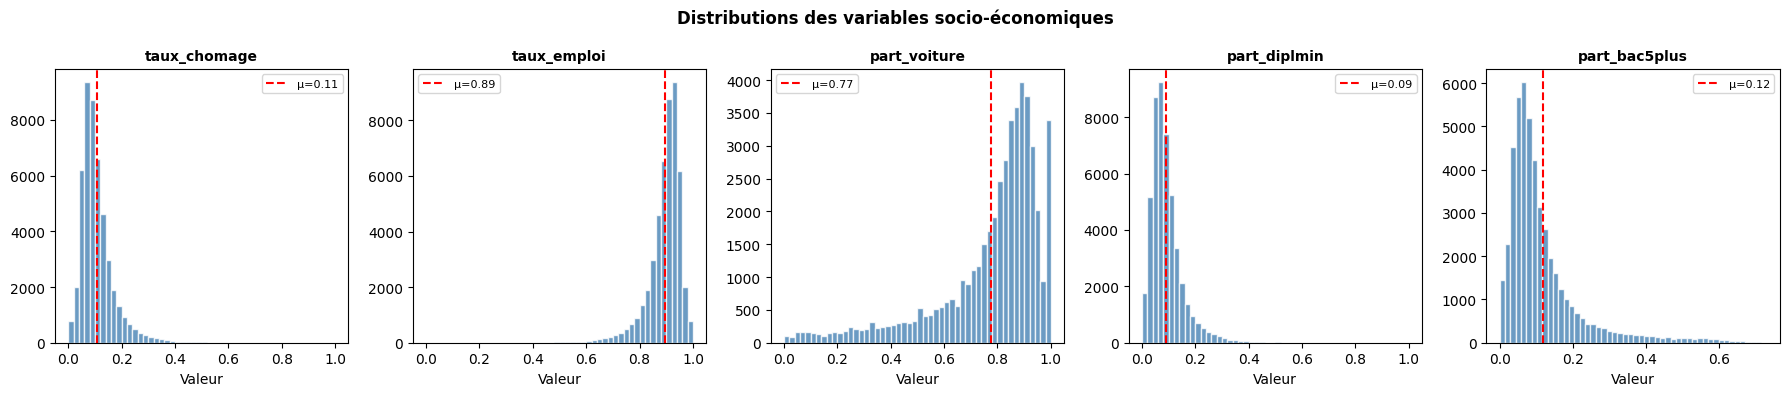

In [ ]:
# Visualisation des distributions
vars_plot = ["taux_chomage", "taux_emploi", "part_voiture",
             "part_diplmin", "part_bac5plus"]

fig, axes = plt.subplots(1, len(vars_plot), figsize=(18, 4))
for ax, var in zip(axes, vars_plot):
    data = iris[var].dropna()
    ax.hist(data, bins=50, color='steelblue', edgecolor='white', alpha=0.8)
    ax.axvline(data.mean(), color='red', linestyle='--',
               label=f'μ={data.mean():.2f}')
    ax.set_title(var, fontsize=10, fontweight='bold')
    ax.legend(fontsize=8)
    ax.set_xlabel("Valeur")

plt.suptitle("Distributions des variables socio-économiques", fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Données de revenus FILO 2021

In [ ]:
revenu_disp = pd.read_csv(
    BASE + "BASE_TD_FILO_IRIS_2021_DISP.csv",
    sep=";", low_memory=False
)
print(f" FILO IRIS : {revenu_disp.shape}")
print(f"  Colonnes : {list(revenu_disp.columns[:8])}...")

# Normaliser le code IRIS
revenu_disp["IRIS"] = revenu_disp["IRIS"].astype(str).str.zfill(9)

 FILO IRIS : (16026, 30)
  Colonnes : ['IRIS', 'DISP_TP6021', 'DISP_INCERT21', 'DISP_Q121', 'DISP_MED21', 'DISP_Q321', 'DISP_EQ21', 'DISP_D121']...


In [ ]:
# Nettoyer les variables clés — remplacer ns/nd par NaN
vars_filo = ["DISP_MED21", "DISP_D121", "DISP_D921",
             "DISP_TP6021", "DISP_GI21", "DISP_RD21"]

for col in vars_filo:
    if col in revenu_disp.columns:
        revenu_disp[col] = revenu_disp[col].replace(
            ["ns", "nd", "s", ""], None
        )
        revenu_disp[col] = pd.to_numeric(
            revenu_disp[col], errors="coerce"
        )

print(" Variables FILO nettoyées")
print("\nStatistiques DISP_MED21 :")
print(revenu_disp["DISP_MED21"].describe().round(0))

 Variables FILO nettoyées

Statistiques DISP_MED21 :
count    14490.0
mean     23257.0
std       6200.0
min      10860.0
25%      19170.0
50%      22380.0
75%      25998.0
max      65140.0
Name: DISP_MED21, dtype: float64


In [ ]:
# Jointure IRIS ← FILO
iris = iris.drop(columns=["DISP_MED21"], errors="ignore")
iris = iris.merge(
    revenu_disp[["IRIS"] + [c for c in vars_filo if c in revenu_disp.columns]],
    on="IRIS",
    how="left"
)

print(f" Après jointure FILO : {iris.shape}")
print(f"\nNaN DISP_MED21 par type IRIS :")
print(iris.groupby("TYP_IRIS")["DISP_MED21"].apply(
    lambda x: x.isna().mean()
).round(2))

 Après jointure FILO : (48046, 29)

NaN DISP_MED21 par type IRIS :
TYP_IRIS
H    0.05
Z    1.00
Name: DISP_MED21, dtype: float64


### 4.1 Fallback revenu communal pour les IRIS de type Z

In [ ]:

import pandas as pd

# Si c'est un Excel (plusieurs onglets)
filo_com = pd.read_csv(
    BASE + "DS_FILOSOFI_CC_data.csv",
    dtype={"GEO": str},
    na_values=["s", "nd", "ns", ""],
    sep=";"
)

# Identifier les colonnes disponibles
print(filo_com.columns.tolist())

# Étape 1 — Voir tous les codes disponibles
print("Codes FILOSOFI_MEASURE disponibles :")
print(filo_com["FILOSOFI_MEASURE"].unique())

print(f"\nNombre de communes : {filo_com['GEO'].nunique():,}")
print(f"Nombre de lignes total : {len(filo_com):,}")

['GEO', 'GEO_OBJECT', 'FILOSOFI_MEASURE', 'UNIT_MEASURE', 'UNIT_MULT', 'CONF_STATUS', 'OBS_STATUS', 'TIME_PERIOD', 'OBS_VALUE']
Codes FILOSOFI_MEASURE disponibles :
['S_SOC_BEN_DI' 'S_SOC_BEN_DI_MIN_SOC' 'S_SOC_BEN_DI_FAM_BEN' 'NUM_PER'
 'S_EI_DI' 'S_DIR_TAX_DI' 'S_EI_DI_UNE' 'S_EI_DI_N_SAL' 'NUM_CU' 'PR_MD60'
 'IR_D9_D1_SL' 'S_INC_ASS_DI' 'MED_SL' 'D1_SL' 'S_SOC_BEN_DI_HOU_BEN'
 'NUM_HH' 'S_HH_TAX' 'D9_SL' 'S_EI_DI_SAL' 'S_RET_PEN_DI']

Nombre de communes : 37,812
Nombre de lignes total : 833,400


In [ ]:
# Extraire la médiane communale
CODE_MED = "MED_SL"

filo_med = filo_com[
    filo_com["FILOSOFI_MEASURE"] == CODE_MED
][["GEO", "OBS_VALUE"]].copy()

filo_med.columns = ["COM", "MED21_COM"]
filo_med["COM"] = filo_med["COM"].astype(str).str.zfill(5)
filo_med["MED21_COM"] = pd.to_numeric(
    filo_med["MED21_COM"], errors="coerce"
)

print(f"✓ Communes extraites  : {len(filo_med):,}")
print(f"  NaN sur MED21_COM   : {filo_med['MED21_COM'].isna().sum():,}")
print(f"  Min / Max           : {filo_med['MED21_COM'].min():.0f} / {filo_med['MED21_COM'].max():.0f} €")

✓ Communes extraites  : 41,670
  NaN sur MED21_COM   : 3,593
  Min / Max           : 12260 / 55340 €


In [ ]:
# Fallback niveau 2 — communal
iris["COM"] = iris["IRIS"].str[:5]
iris = iris.merge(filo_med, on="COM", how="left")
iris["DISP_MED21"] = iris["DISP_MED21"].fillna(iris["MED21_COM"])
iris = iris.drop(columns=["MED21_COM"])
n2 = iris["DISP_MED21"].isna().mean()
print(f"Après fallback communal    : {n2:.1%} NaN")

# Fallback niveau 3 — départemental (Guadeloupe, Guyane, Mayotte absents de Filosofi)
revenu_dep = (
    iris[iris["DISP_MED21"].notna()]
    .groupby("DEP")["DISP_MED21"]
    .median()
    .reset_index()
    .rename(columns={"DISP_MED21": "DISP_MED21_dep"})
)
iris = iris.merge(revenu_dep, on="DEP", how="left")
iris["DISP_MED21"] = iris["DISP_MED21"].fillna(iris["DISP_MED21_dep"])
iris = iris.drop(columns=["DISP_MED21_dep"])
n3 = iris["DISP_MED21"].isna().mean()
print(f"Après fallback département : {n3:.1%} NaN")
print(f"\n✓ Objectif atteint ? {'OUI ✓' if n3 < 0.05 else 'NON — vérifier'}")

Après fallback communal    : 6.5% NaN
Après fallback département : 0.0% NaN

✓ Objectif atteint ? OUI ✓


In [ ]:
# Extraire D9/D1 (inégalités) et taux de pauvreté en même temps
vars_filo_extra = {
    "IR_D9_D1_SL": "ratio_d9_d1",   # inégalités locales
    "PR_MD60":     "taux_pauvrete",  # taux de pauvreté à 60%
    "D1_SL":       "d1_revenu",      # 1er décile
    "D9_SL":       "d9_revenu",      # 9ème décile
}

filo_extras = {}
for code, nom in vars_filo_extra.items():
    df_tmp = filo_com[
        filo_com["FILOSOFI_MEASURE"] == code
    ][["GEO","OBS_VALUE"]].copy()
    df_tmp.columns = ["COM", nom]
    df_tmp["COM"] = df_tmp["COM"].astype(str).str.zfill(5)
    df_tmp[nom] = pd.to_numeric(df_tmp[nom], errors="coerce")
    filo_extras[nom] = df_tmp
    print(f"✓ {nom:<20} : {df_tmp[nom].notna().sum():,} communes")

# Joindre toutes les variables extras
from functools import reduce
filo_all = reduce(
    lambda a, b: pd.merge(a, b, on="COM", how="outer"),
    filo_extras.values()
)
print(f"\n✓ Table Filosofi étendue : {filo_all.shape}")
print(filo_all.head(3))

✓ ratio_d9_d1          : 12,142 communes
✓ taux_pauvrete        : 10,933 communes
✓ d1_revenu            : 12,142 communes
✓ d9_revenu            : 12,142 communes

✓ Table Filosofi étendue : (113648, 5)
     COM  ratio_d9_d1  taux_pauvrete  d1_revenu  d9_revenu
0  00001          4.3           15.8    11570.0    49910.0
1  00001          4.3           15.8    11570.0    46760.0
2  00001          4.3           15.8    13510.0    49910.0


In [ ]:
# Dédupliquer filo_all avant la jointure
filo_all = filo_all.drop_duplicates(subset="COM", keep="first")
print(f"filo_all après dédup : {len(filo_all):,} communes")
# puis iris = iris.merge(filo_all, on="COM", how="left")

filo_all après dédup : 37,479 communes


In [ ]:
# Joindre à iris avec fallback département pour chaque variable
iris = iris.merge(filo_all, on="COM", how="left")

for var in vars_filo_extra.values():
    if var in iris.columns:
        # Fallback département
        dep_med = (
            iris[iris[var].notna()]
            .groupby("DEP")[var].median()
            .reset_index().rename(columns={var: f"{var}_dep"})
        )
        iris = iris.merge(dep_med, on="DEP", how="left")
        iris[var] = iris[var].fillna(iris[f"{var}_dep"])
        iris = iris.drop(columns=[f"{var}_dep"])
        nan_pct = iris[var].isna().mean() * 100
        print(f"  {var:<20} : {nan_pct:.1f}% NaN")

  ratio_d9_d1          : 0.0% NaN
  taux_pauvrete        : 0.0% NaN
  d1_revenu            : 0.0% NaN
  d9_revenu            : 0.0% NaN


In [ ]:
vars_finales = [
    "taux_chomage", "taux_emploi",
    "part_voiture", "part_tcom",
    "part_diplmin", "part_bac2", "part_bac34", "part_bac5plus",
    "DISP_MED21", "taux_pauvrete", "ratio_d9_d1",
    "d1_revenu", "d9_revenu"
]

print("=" * 55)
print("VARIABLES FINALES POUR L'AGRÉGATION")
print("=" * 55)
for v in vars_finales:
    if v in iris.columns:
        nan = iris[v].isna().mean() * 100
        nan_summary = iris[v].isna().sum()
        moy = iris[v].mean()
        print(f"  ✓ {v:<25} moy={moy:>8.1f}  {nan_summary} NaN={nan:.1f}%")
    else:
        print(f"  ✗ {v:<25} MANQUANT")

VARIABLES FINALES POUR L'AGRÉGATION
  ✓ taux_chomage              moy=     0.1  9 NaN=0.0%
  ✓ taux_emploi               moy=     0.9  9 NaN=0.0%
  ✓ part_voiture              moy=     0.8  104 NaN=0.2%
  ✓ part_tcom                 moy=     0.1  104 NaN=0.2%
  ✓ part_diplmin              moy=     0.1  9 NaN=0.0%
  ✓ part_bac2                 moy=     0.1  9 NaN=0.0%
  ✓ part_bac34                moy=     0.1  9 NaN=0.0%
  ✓ part_bac5plus             moy=     0.1  9 NaN=0.0%
  ✓ DISP_MED21                moy= 22900.5  0 NaN=0.0%
  ✓ taux_pauvrete             moy=    15.7  0 NaN=0.0%
  ✓ ratio_d9_d1               moy=     3.2  0 NaN=0.0%
  ✓ d1_revenu                 moy= 12269.5  0 NaN=0.0%
  ✓ d9_revenu                 moy= 39382.8  0 NaN=0.0%


In [ ]:
# Identifier les IRIS avec NaN sur part_voiture
iris_nan_voit = iris[iris["part_voiture"].isna()]
print(f"IRIS avec NaN part_voiture : {len(iris_nan_voit)}")
print(iris_nan_voit[["IRIS","COM","DEP","TYP_IRIS","C22_ACTOCC15P"]].head(10))

IRIS avec NaN part_voiture : 104
           IRIS    COM DEP TYP_IRIS  C22_ACTOCC15P
1258  026090000  02609  02        Z            0.0
2154  041070000  04107  04        Z            0.0
2155  041070000  04107  04        Z            0.0
2356  050510000  05051  05        Z            0.0
2405  050660000  05066  05        Z            0.0
3881  081970000  08197  08        Z            0.0
3974  083000000  08300  08        Z            0.0
4286  090370000  09037  09        Z            0.0
4332  090830000  09083  09        Z            0.0
4405  091430000  09143  09        Z            0.0


In [ ]:
iris_pb = iris[iris["part_voiture"].isna()]
print(f"Population moyenne : {iris_pb['P22_POP1564'].mean():.0f}")
print(f"IRIS avec pop = 0  : {(iris_pb['P22_POP1564'] == 0).sum()}")
print(f"IRIS avec pop > 0  : {(iris_pb['P22_POP1564'] > 0).sum()}")

Population moyenne : 14
IRIS avec pop = 0  : 9
IRIS avec pop > 0  : 95


In [ ]:
# Fallback part_voiture et part_tcom par département
for var in ["part_voiture", "part_tcom"]:
    dep_med = (
        iris[iris[var].notna()]
        .groupby("DEP")[var]
        .median()
        .reset_index()
        .rename(columns={var: f"{var}_dep"})
    )
    iris = iris.merge(dep_med, on="DEP", how="left")
    iris[var] = iris[var].fillna(iris[f"{var}_dep"])
    iris = iris.drop(columns=[f"{var}_dep"])
    print(f"✓ {var:<20} NaN après fallback : {iris[var].isna().sum()}")

✓ part_voiture         NaN après fallback : 0
✓ part_tcom            NaN après fallback : 0


In [ ]:
print("=" * 55)
print("CONTRÔLE QUALITÉ FINAL")
print("=" * 55)
for v in vars_finales:
    if v in iris.columns:
        nan_n   = iris[v].isna().sum()
        nan_pct = iris[v].isna().mean() * 100
        moy     = iris[v].mean()
        statut  = "✓" if nan_pct == 0 else "⚠️"
        print(f"  {statut} {v:<25} moy={moy:>8.1f}  NaN={nan_n} ({nan_pct:.1f}%)")

print(f"\n  IRIS total : {len(iris):,}")
print(f"  Variables  : {len([v for v in vars_finales if v in iris.columns])}")
print(f"\n→ Prêt pour l'export et l'agrégation spatiale ✓")

CONTRÔLE QUALITÉ FINAL
  ⚠️ taux_chomage              moy=     0.1  NaN=9 (0.0%)
  ⚠️ taux_emploi               moy=     0.9  NaN=9 (0.0%)
  ✓ part_voiture              moy=     0.8  NaN=0 (0.0%)
  ✓ part_tcom                 moy=     0.1  NaN=0 (0.0%)
  ⚠️ part_diplmin              moy=     0.1  NaN=9 (0.0%)
  ⚠️ part_bac2                 moy=     0.1  NaN=9 (0.0%)
  ⚠️ part_bac34                moy=     0.1  NaN=9 (0.0%)
  ⚠️ part_bac5plus             moy=     0.1  NaN=9 (0.0%)
  ✓ DISP_MED21                moy= 22900.5  NaN=0 (0.0%)
  ✓ taux_pauvrete             moy=    15.7  NaN=0 (0.0%)
  ✓ ratio_d9_d1               moy=     3.2  NaN=0 (0.0%)
  ✓ d1_revenu                 moy= 12269.5  NaN=0 (0.0%)
  ✓ d9_revenu                 moy= 39382.8  NaN=0 (0.0%)

  IRIS total : 58,772
  Variables  : 13

→ Prêt pour l'export et l'agrégation spatiale ✓


In [ ]:
# Fallback département pour les 9 IRIS restants
vars_act = ["taux_chomage", "taux_emploi",
            "part_diplmin", "part_bac2", "part_bac34", "part_bac5plus"]

for var in vars_act:
    dep_med = (
        iris[iris[var].notna()]
        .groupby("DEP")[var]
        .median()
        .reset_index()
        .rename(columns={var: f"{var}_dep"})
    )
    iris = iris.merge(dep_med, on="DEP", how="left")
    iris[var] = iris[var].fillna(iris[f"{var}_dep"])
    iris = iris.drop(columns=[f"{var}_dep"])

# Vérification rapide
nan_total = sum(iris[v].isna().sum() for v in vars_finales if v in iris.columns)
print(f"✓ NaN restants sur toutes les variables : {nan_total}")
print(f"  (doit être 0)")

✓ NaN restants sur toutes les variables : 0
  (doit être 0)


In [ ]:
# Vérifier les doublons
print(f"IRIS total          : {len(iris):,}")
print(f"IRIS uniques        : {iris['IRIS'].nunique():,}")
print(f"Doublons            : {len(iris) - iris['IRIS'].nunique():,}")

# Si doublons → dédupliquer
if iris['IRIS'].duplicated().sum() > 0:
    iris = iris.drop_duplicates(subset="IRIS", keep="first")
    print(f"✓ Après déduplication : {len(iris):,} IRIS")

IRIS total          : 58,772
IRIS uniques        : 48,046
Doublons            : 10,726
✓ Après déduplication : 48,046 IRIS


In [ ]:
# Vérifier que les valeurs sont cohérentes après déduplication
print(f"✓ IRIS après dédup : {len(iris):,}")
print(f"  Attendu          : ~36 000 (H + Z résidentiels)")
print()

# Contrôle final complet
print("=" * 55)
print("CONTRÔLE QUALITÉ FINAL APRÈS DÉDUPLICATION")
print("=" * 55)
for v in vars_finales:
    if v in iris.columns:
        nan_n   = iris[v].isna().sum()
        nan_pct = iris[v].isna().mean() * 100
        moy     = iris[v].mean()
        statut  = "✓" if nan_n == 0 else "⚠️"
        print(f"  {statut} {v:<25} moy={moy:>8.1f}  NaN={nan_n} ({nan_pct:.1f}%)")

print(f"\n  Type H : {(iris['TYP_IRIS']=='H').sum():,}")
print(f"  Type Z : {(iris['TYP_IRIS']=='Z').sum():,}")

✓ IRIS après dédup : 48,046
  Attendu          : ~36 000 (H + Z résidentiels)

CONTRÔLE QUALITÉ FINAL APRÈS DÉDUPLICATION
  ✓ taux_chomage              moy=     0.1  NaN=0 (0.0%)
  ✓ taux_emploi               moy=     0.9  NaN=0 (0.0%)
  ✓ part_voiture              moy=     0.8  NaN=0 (0.0%)
  ✓ part_tcom                 moy=     0.1  NaN=0 (0.0%)
  ✓ part_diplmin              moy=     0.1  NaN=0 (0.0%)
  ✓ part_bac2                 moy=     0.1  NaN=0 (0.0%)
  ✓ part_bac34                moy=     0.1  NaN=0 (0.0%)
  ✓ part_bac5plus             moy=     0.1  NaN=0 (0.0%)
  ✓ DISP_MED21                moy= 23149.8  NaN=0 (0.0%)
  ✓ taux_pauvrete             moy=    15.7  NaN=0 (0.0%)
  ✓ ratio_d9_d1               moy=     3.2  NaN=0 (0.0%)
  ✓ d1_revenu                 moy= 12273.4  NaN=0 (0.0%)
  ✓ d9_revenu                 moy= 39508.2  NaN=0 (0.0%)

  Type H : 15,010
  Type Z : 33,036


In [ ]:
# BONNE PRATIQUE — vérifier avant chaque merge
def merge_safe(left, right, on, how="left", name="table"):
    dupes = right[on].duplicated().sum()
    if dupes > 0:
        print(f"⚠️  {name} a {dupes} doublons sur '{on}' — déduplication automatique")
        right = right.drop_duplicates(subset=on, keep="first")
    result = left.merge(right, on=on, how=how)
    if len(result) != len(left):
        print(f"⚠️  Jointure {name} : {len(left)} → {len(result)} lignes !")
    return result

In [ ]:
vars_export = [
    "IRIS", "COM", "DEP", "TYP_IRIS",
    "P22_POP1564", "P22_ACT1564",
    "taux_chomage", "taux_emploi",
    "part_voiture", "part_tcom",
    "part_diplmin", "part_bac2", "part_bac34", "part_bac5plus",
    "DISP_MED21", "taux_pauvrete", "ratio_d9_d1",
    "d1_revenu", "d9_revenu",
]

iris_final = iris[[v for v in vars_export if v in iris.columns]].copy()

print(f"✓ Dimensions finales : {iris_final.shape}")
print(f"  IRIS uniques       : {iris_final['IRIS'].nunique():,}")
print(f"  NaN total          : {iris_final.isna().sum().sum()}")
print(f"  Type H             : {(iris_final['TYP_IRIS']=='H').sum():,}")
print(f"  Type Z             : {(iris_final['TYP_IRIS']=='Z').sum():,}")

iris_final.to_csv(BASE + "iris_socio_final.csv", index=False)
print(f"\n✓ Exporté : iris_socio_final.csv")
print(f"  Prochaine étape : agrégation spatiale Voronoï × IRIS")

✓ Dimensions finales : (48046, 19)
  IRIS uniques       : 48,046
  NaN total          : 0
  Type H             : 15,010
  Type Z             : 33,036

✓ Exporté : iris_socio_final.csv
  Prochaine étape : agrégation spatiale Voronoï × IRIS


In [ ]:
# Combien d'IRIS dans le Lyon 1er arrondissement ?
iris_lyon1 = iris_final[iris_final["COM"] == "69381"]
print(f"IRIS dans Lyon 1er (69381) : {len(iris_lyon1)}")
print(iris_lyon1[["IRIS","TYP_IRIS"]].to_string(index=False))

IRIS dans Lyon 1er (69381) : 10
     IRIS TYP_IRIS
693810101        H
693810201        H
693810202        H
693810301        H
693810302        H
693810303        H
693810304        H
693810401        H
693810402        H
693810501        H
